# 3. Transformer (mini-GPT) od zera

**Teoria do tego notebooka:** [`03_transformer.md`](03_transformer.md)

Plan:

1. scaled dot-product attention na małym przykładzie, krok po kroku,
2. mini-GPT: multi-head causal self-attention + MLP + Pre-LN + rezydua,
3. trening i porównanie z RNN i LSTM,
4. podgląd wag uwagi na prawdziwym tekście,
5. KV cache: generowanie bez przeliczania wszystkiego od nowa,
6. **cena**: koszt jednego tokenu i pamięć rosną z długością kontekstu (wrócimy do tego przy RWKV),
7. zadanie pamięciowe.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from common import (MEMORY_VOCAB, count_params, load_results, plot_memory, prepare_data,
                    run_memory_experiment, sample_from_logits, save_results, set_seed, time_fn,
                    train, TrainConfig)

plt.rcParams["figure.dpi"] = 110
tok, train_data, val_data = prepare_data()

## 1. Attention na małym przykładzie

5 tokenów, wymiar 4. Każdy token ma zapytanie $q$, klucz $k$ i wartość $v$. Wynik dla tokenu $t$ to średnia
wartości $v_i$ ($i \le t$), ważona przez $\operatorname{softmax}_i(q_t \cdot k_i / \sqrt{d})$.

In [2]:
set_seed(0)
T, d = 5, 4
q, k, v = torch.randn(T, d), torch.randn(T, d), torch.randn(T, d)

scores = q @ k.T / math.sqrt(d)
mask = torch.ones(T, T, dtype=torch.bool).tril()
weights = scores.masked_fill(~mask, float("-inf")).softmax(dim=-1)
out = weights @ v

torch.set_printoptions(precision=2, sci_mode=False)
print("wyniki q·k/√d:\n", scores)
print("\npo masce i softmaksie (każdy wiersz sumuje się do 1):\n", weights)
print("\nwyjście = wagi @ V, kształt", tuple(out.shape))

wyniki q·k/√d:
 tensor([[-0.49,  0.34, -1.16,  0.75,  0.61],
        [ 0.34, -0.01, -1.66, -0.99,  0.85],
        [ 0.62, -0.40,  0.31, -0.44,  0.16],
        [ 0.51, -0.25,  2.13, -0.60, -1.54],
        [ 0.93, -0.78,  1.74, -0.58, -0.34]])

po masce i softmaksie (każdy wiersz sumuje się do 1):
 tensor([[1.00, 0.00, 0.00, 0.00, 0.00],
        [0.59, 0.41, 0.00, 0.00, 0.00],
        [0.48, 0.17, 0.35, 0.00, 0.00],
        [0.15, 0.07, 0.74, 0.05, 0.00],
        [0.25, 0.05, 0.57, 0.06, 0.07]])

wyjście = wagi @ V, kształt (5, 4)


## 2. Mini-GPT

Multi-head attention: dzielimy wymiar `d_model` na `n_head` głów, każda liczy własną uwagę na wymiarze
`d_model / n_head`, wyniki sklejamy i rzutujemy macierzą `proj`.

Metoda `step` liczy **jeden nowy token** z użyciem **KV cache**: klucze i wartości poprzednich tokenów
trzymamy w preallokowanych tensorach, więc nie liczymy ich od nowa.

In [3]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_head):
        super().__init__()
        self.n_head = n_head
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)

    def _heads(self, x):
        B, T, C = x.shape
        return [t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in self.qkv(x).split(C, dim=2)]

    def forward(self, x, return_weights=False):
        B, T, C = x.shape
        q, k, v = self._heads(x)                                       # każde: (B, n_head, T, d_head)
        scores = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))      # (B, n_head, T, T)
        mask = torch.ones(T, T, dtype=torch.bool, device=x.device).tril()
        weights = scores.masked_fill(~mask, float("-inf")).softmax(dim=-1)
        y = self.proj((weights @ v).transpose(1, 2).reshape(B, T, C))
        return (y, weights) if return_weights else y

    def step(self, x, cache, pos):
        """x: (B, 1, C) – jeden nowy token na pozycji pos; cache: {'k','v'} o kształcie (B, n_head, T_max, d_head)."""
        B, _, C = x.shape
        q, k, v = self._heads(x)
        cache["k"][:, :, pos] = k[:, :, 0]
        cache["v"][:, :, pos] = v[:, :, 0]
        K, V = cache["k"][:, :, : pos + 1], cache["v"][:, :, : pos + 1]
        weights = (q @ K.transpose(-2, -1) / math.sqrt(q.size(-1))).softmax(dim=-1)   # (B, n_head, 1, pos+1)
        return self.proj((weights @ V).transpose(1, 2).reshape(B, 1, C))


class Block(nn.Module):
    def __init__(self, d_model, n_head):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_head)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))

    def step(self, x, cache, pos):
        x = x + self.attn.step(self.ln1(x), cache, pos)
        return x + self.mlp(self.ln2(x))


class GPT(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_layer=4, n_head=4, block_size=128):
        super().__init__()
        self.n_head, self.block_size = n_head, block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)
        self.blocks = nn.ModuleList([Block(d_model, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("attn.proj.weight") or name.endswith("mlp.2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * n_layer))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx):
        T = idx.shape[1]
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln_f(x))

    def new_cache(self, batch_size, max_len):
        d_head = self.tok_emb.embedding_dim // self.n_head
        shape = (batch_size, self.n_head, max_len, d_head)
        return [{"k": torch.zeros(shape), "v": torch.zeros(shape)} for _ in self.blocks]

    def step(self, token, cache, pos):
        """token: (B,) – logity następnego tokenu po dopisaniu `token` na pozycji `pos`."""
        x = self.tok_emb(token)[:, None] + self.pos_emb.weight[pos]
        for block, block_cache in zip(self.blocks, cache):
            x = block.step(x, block_cache, pos)
        return self.head(self.ln_f(x))[:, 0]

Dwa szczegóły inicjalizacji w stylu GPT-2, oba dla stabilności treningu:
wszystkie wagi z $\mathcal{N}(0, 0{,}02)$, a projekcje wpisujące do strumienia rezydualnego (`attn.proj`,
druga warstwa MLP) dodatkowo przeskalowane przez $1/\sqrt{2 \cdot n_{layer}}$, żeby suma wkładów wszystkich
warstw na starcie nie rosła z głębokością.

## 3. Trening

In [4]:
set_seed(1337)
model = GPT(tok.vocab_size)
print(f"parametry: {count_params(model):,}".replace(",", " "))
cfg = TrainConfig(lr=4e-3)
hist = train(model, train_data, val_data, cfg)

parametry: 832 000


krok     0 | train   -   | val 4.479 |    0.0s


krok   100 | train 2.920 | val 2.583 |   14.4s


krok   200 | train 2.538 | val 2.521 |   28.1s


krok   300 | train 2.418 | val 2.340 |   43.9s


...

krok   600 | train 2.017 | val 2.032 |   90.7s


krok   700 | train 1.934 | val 1.963 |  104.4s


krok   800 | train 1.866 | val 1.919 |  118.4s


krok   900 | train 1.812 | val 1.883 |  132.1s


krok  1000 | train 1.768 | val 1.861 |  145.9s


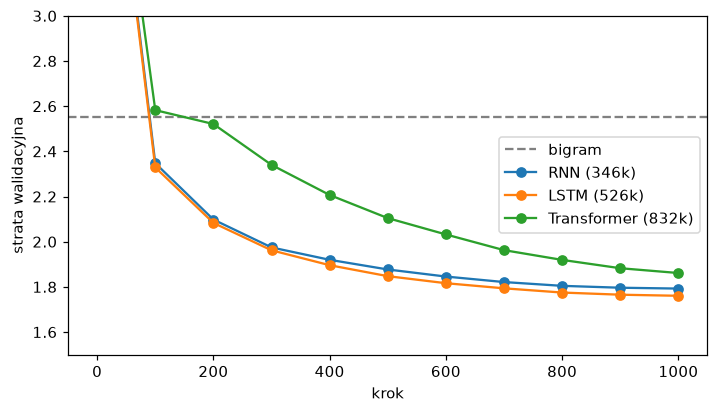

Transformer: 1.861, 146 ms/krok


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4))
bigram = load_results("00_bigram")
if bigram:
    ax.axhline(bigram["val_loss"][-1], color="gray", ls="--", label="bigram")
for name in ("01_rnn", "02_lstm"):
    r = load_results(name)
    if r:
        ax.plot(r["eval_step"], r["val_loss"], "o-", label=f"{r['name']} ({r['n_params'] / 1e3:.0f}k)")
ax.plot(hist["eval_step"], hist["val_loss"], "o-", label=f"Transformer ({hist['n_params'] / 1e3:.0f}k)")
ax.set_ylim(1.5, 3.0)
ax.set_xlabel("krok")
ax.set_ylabel("strata walidacyjna")
ax.legend()
plt.show()
print(f"Transformer: {hist['val_loss'][-1]:.3f}, {hist['sec_per_step'] * 1000:.0f} ms/krok")

Ciekawa obserwacja: przez pierwsze ~200 kroków Transformer stoi w miejscu na poziomie modelu bigramowego.
Zanim zacznie korzystać z kontekstu, musi się nauczyć **pozycji** (embeddingi pozycji startują losowo)
i wzorców uwagi. RNN dostaje kolejność "za darmo" z samej rekurencji.

W tak małej skali (milion parametrów, 4 mln tokenów treningu) wszystkie trzy architektury lądują blisko siebie.
Przewagi Transformera to przede wszystkim **równoległy trening** (na GPU różnica jest ogromna)
i **bezstratny dostęp do kontekstu**, co widać przy dalekich zależnościach i przy dużej skali.

## 4. Na co patrzą głowy uwagi?

Wagi uwagi dla 64 znaków tekstu walidacyjnego, każda głowa w każdej warstwie.
Wiersz = token, który "pyta"; kolumna = token, na który patrzy.

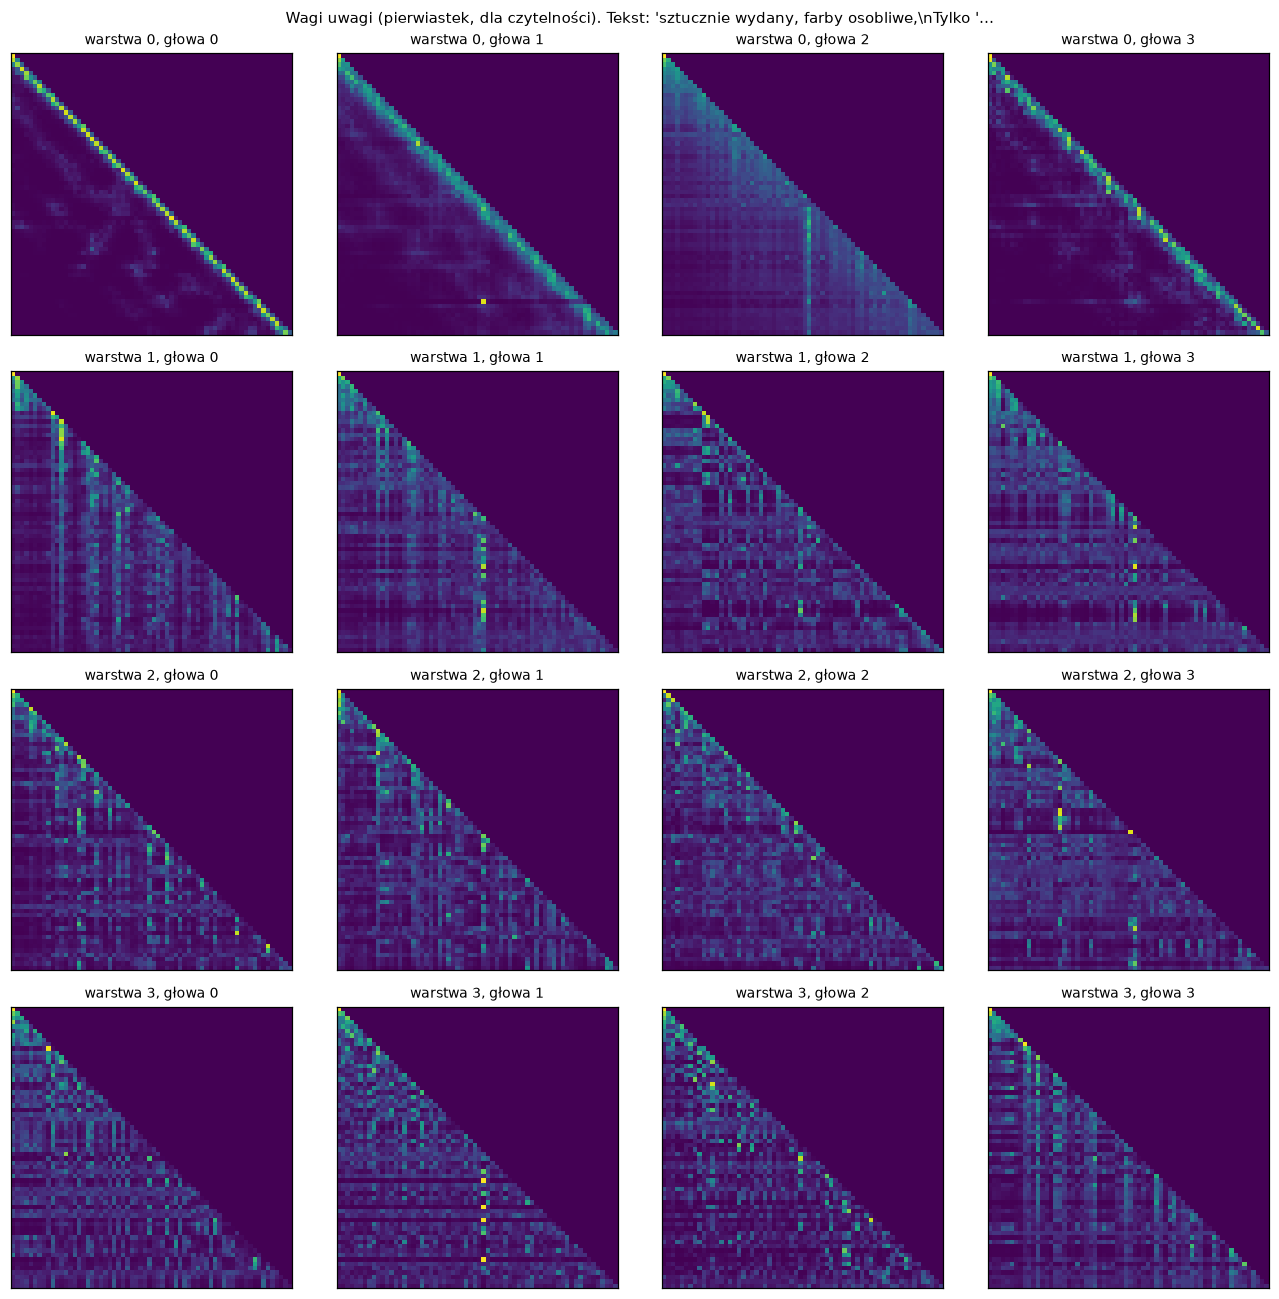

In [6]:
snippet = val_data[3000:3064]
model.eval()
with torch.no_grad():
    x = model.tok_emb(snippet[None]) + model.pos_emb(torch.arange(len(snippet)))
    all_weights = []
    for block in model.blocks:
        _, w = block.attn(block.ln1(x), return_weights=True)
        all_weights.append(w[0])
        x = block(x)
model.train()

n_layer, n_head = len(all_weights), all_weights[0].shape[0]
fig, axes = plt.subplots(n_layer, n_head, figsize=(3 * n_head, 3 * n_layer))
for layer in range(n_layer):
    for head in range(n_head):
        ax = axes[layer, head]
        ax.imshow(all_weights[layer][head].sqrt(), cmap="viridis")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"warstwa {layer}, głowa {head}", fontsize=9)
plt.suptitle("Wagi uwagi (pierwiastek, dla czytelności). Tekst: " + repr(tok.decode(snippet[:40])) + "...", fontsize=10)
plt.tight_layout()
plt.show()

Typowo widać głowy patrzące na **poprzedni znak** (linia tuż pod przekątną), na **początek słowa**
lub ostatnią spację, a w wyższych warstwach wzory bardziej rozproszone. Każda głowa sama ustala,
na co patrzy, i może to zależeć od treści. RWKV-4 tego nie potrafi (jego "uwaga" ma z góry zadany kształt
zaniku), co zobaczymy w rozdziale 4.

## 5. KV cache: generowanie token po tokenie

Bez cache przy każdym nowym tokenie przeliczalibyśmy klucze i wartości **wszystkich** poprzednich tokenów.
Z cache liczymy tylko nowy token, ale **musi on spojrzeć na cały zapamiętany kontekst**.

Najpierw sprawdzamy poprawność: logity z pełnego przebiegu i z kolejnych wywołań `step` muszą być takie same.

In [7]:
model.eval()
seq = val_data[:50][None]
with torch.no_grad():
    full = model(seq)[0]
    cache = model.new_cache(1, seq.shape[1])
    incremental = torch.stack([model.step(seq[:, t], cache, t)[0] for t in range(seq.shape[1])])
print("max różnica logitów (pełny przebieg vs KV cache):", (full - incremental).abs().max().item())


@torch.no_grad()
def generate_gpt(model, prompt, n_new, temperature=0.8, seed=0):
    g = torch.Generator().manual_seed(seed)
    ids = tok.encode(prompt)
    cache = model.new_cache(1, model.block_size)
    for pos, t in enumerate(ids):
        logits = model.step(torch.tensor([t]), cache, pos)
    out = list(ids)
    for pos in range(len(ids), min(len(ids) + n_new, model.block_size)):
        nxt = sample_from_logits(logits, temperature, generator=g)
        out.append(nxt.item())
        logits = model.step(nxt[:, 0], cache, pos)
    return tok.decode(out)


sample = generate_gpt(model, "Litwo! Ojczyzno moja! ", 400)
print(sample)
model.train()
save_results("03_transformer", {"name": "Transformer", **hist, "sample": sample})

max różnica logitów (pełny przebieg vs KV cache): 6.67572021484375e-06
Litwo! Ojczyzno moja! to za to piękną szczękę
Na zabawić zakliwać i bez wkoło. Nieraz młodem
Majoruchając rękę Sędzia ochany.
Sz


PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/03_transformer.json')

Uwaga: nasz GPT ma uczone embeddingi pozycji tylko do `block_size = 128`, więc nie umie generować dłużej
niż 128 znaków (stąd krótszy tekst). Prawdziwe modele mają kontekst rzędu tysięcy tokenów, a do dłuższego
generowania używa się przesuwanego okna albo kodowań pozycji typu RoPE.

## 6. Cena: koszt jednego tokenu rośnie z kontekstem

Bierzemy większy, niewytrenowany GPT (`d_model = 256`, 4 warstwy) z kontekstem do 32 768 tokenów.
Zapełniamy KV cache losowymi wartościami do długości `t` i mierzymy czas wygenerowania **jednego** tokenu.
Wagi nie mają znaczenia dla czasu, liczy się tylko kształt obliczeń.
**Te same ustawienia użyjemy dla RWKV w rozdziale 4.**

In [8]:
BENCH = {"d_model": 256, "n_layer": 4, "contexts": [128, 512, 2048, 8192, 32768]}
set_seed(0)
bench_model = GPT(tok.vocab_size, BENCH["d_model"], BENCH["n_layer"], n_head=4, block_size=max(BENCH["contexts"]) + 1).eval()
cache = bench_model.new_cache(1, max(BENCH["contexts"]) + 1)
for c in cache:
    c["k"].normal_()
    c["v"].normal_()

token = torch.tensor([0])
bench = {"context": [], "ms_per_token": [], "cache_MB": []}
with torch.no_grad():
    for ctx in BENCH["contexts"]:
        ms = time_fn(lambda: bench_model.step(token, cache, ctx), repeats=20, warmup=3) * 1000
        cache_mb = 2 * BENCH["n_layer"] * (ctx + 1) * BENCH["d_model"] * 4 / 2**20
        bench["context"].append(ctx)
        bench["ms_per_token"].append(ms)
        bench["cache_MB"].append(cache_mb)
        print(f"kontekst {ctx:6d}: {ms:6.2f} ms/token, KV cache {cache_mb:7.1f} MB")
save_results("03_transformer_bench", {**BENCH, **bench})

kontekst    128:   0.92 ms/token, KV cache     1.0 MB
kontekst    512:   0.97 ms/token, KV cache     4.0 MB
kontekst   2048:   1.73 ms/token, KV cache    16.0 MB
kontekst   8192:   3.80 ms/token, KV cache    64.0 MB


kontekst  32768:  11.95 ms/token, KV cache   256.0 MB


PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/03_transformer_bench.json')

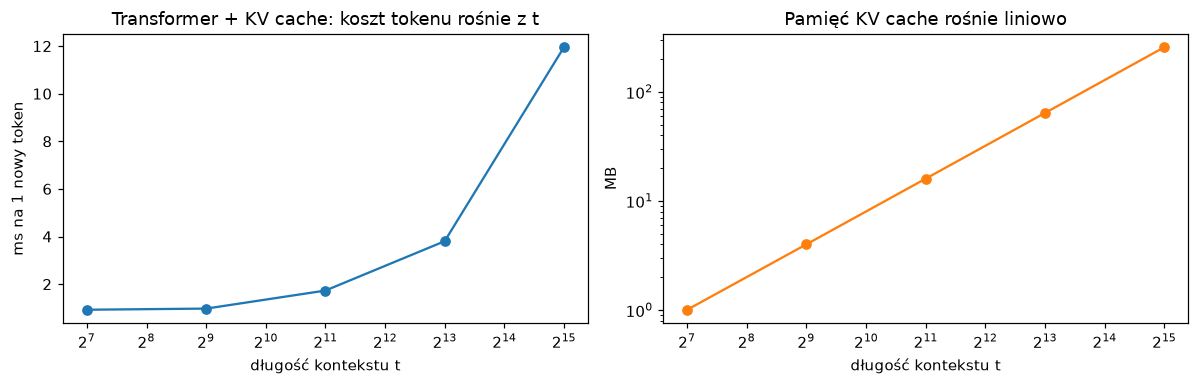

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(bench["context"], bench["ms_per_token"], "o-")
axes[0].set_xscale("log", base=2)
axes[0].set_xlabel("długość kontekstu t")
axes[0].set_ylabel("ms na 1 nowy token")
axes[0].set_title("Transformer + KV cache: koszt tokenu rośnie z t")
axes[1].plot(bench["context"], bench["cache_MB"], "o-", color="C1")
axes[1].set_xscale("log", base=2)
axes[1].set_yscale("log")
axes[1].set_xlabel("długość kontekstu t")
axes[1].set_ylabel("MB")
axes[1].set_title("Pamięć KV cache rośnie liniowo")
plt.tight_layout()
plt.show()

Dla małych kontekstów dominuje stały koszt (projekcje, MLP, narzut Pythona). Przy dziesiątkach tysięcy tokenów
zaczyna dominować attention po całym cache i czas tokenu rośnie liniowo. Łączny koszt wygenerowania $T$ tokenów
rośnie więc jak $O(T^2)$. Dla prawdziwych modeli (d = 4096, 32 warstwy, fp16) KV cache to ok. 0,5 MB **na token**.

A trening? Macierz uwagi ma $T \times T$ elementów na każdą głowę i warstwę:

In [10]:
train_cost = {"T": [], "ms": []}
with torch.no_grad():
    for T in (256, 512, 1024, 2048, 4096):
        idx = torch.randint(tok.vocab_size, (1, T))
        ms = time_fn(lambda: bench_model(idx), repeats=3, warmup=1) * 1000
        train_cost["T"].append(T)
        train_cost["ms"].append(ms)
        print(f"T = {T:5d}: przebieg w przód {ms:8.1f} ms, macierz uwagi {T * T * 4 * 4 / 2**20:6.0f} MB na warstwę")

T =   256: przebieg w przód      8.2 ms, macierz uwagi      1 MB na warstwę
T =   512: przebieg w przód     19.0 ms, macierz uwagi      4 MB na warstwę


T =  1024: przebieg w przód     63.4 ms, macierz uwagi     16 MB na warstwę


T =  2048: przebieg w przód    324.0 ms, macierz uwagi     64 MB na warstwę


T =  4096: przebieg w przód   1186.9 ms, macierz uwagi    256 MB na warstwę


Podwojenie długości sekwencji daje więcej niż dwukrotny wzrost czasu, a pamięć na macierz uwagi rośnie
czterokrotnie. To $O(T^2)$, z którym walczą FlashAttention, sparse attention, linear attention... i RWKV.

## 7. Zadanie pamięciowe

Transformer może spojrzeć bezpośrednio na pierwszy token, więc odległość nie powinna mieć znaczenia.

In [11]:
MEMORY_LENGTHS = [5, 10, 20, 40, 80, 160]
memory = run_memory_experiment(lambda: GPT(MEMORY_VOCAB, d_model=64, n_layer=2, n_head=4, block_size=max(MEMORY_LENGTHS)),
                               MEMORY_LENGTHS, name="Transformer")
save_results("03_transformer_memory", memory)

L =    5: trafność 100% / 100%   kroki treningu:   56 /   56   (0 s)


L =   10: trafność 100% / 100%   kroki treningu:   66 /   64   (1 s)


L =   20: trafność 100% / 100%   kroki treningu:   61 /   67   (1 s)


L =   40: trafność 100% / 100%   kroki treningu:   74 /   73   (3 s)


L =   80: trafność 100% / 100%   kroki treningu:  115 /   92   (9 s)


L =  160: trafność 100% / 100%   kroki treningu:  112 /  410   (69 s)


PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/03_transformer_memory.json')

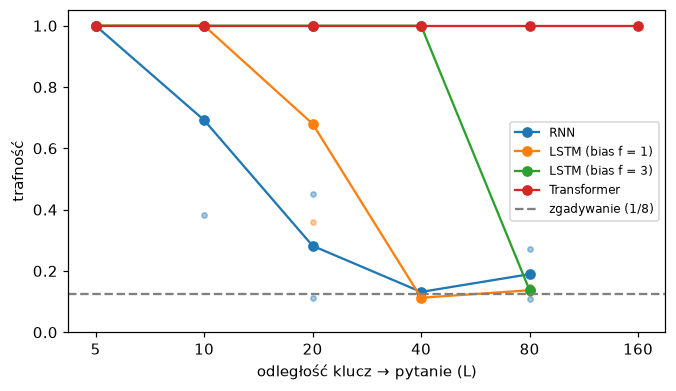

In [12]:
plot_memory([load_results("01_rnn_memory"), load_results("02_lstm_memory"), load_results("02_lstm_memory_fb3"), memory])
plt.show()

Transformer rozwiązuje zadanie przy każdej odległości, zwykle w ok. 100 krokach (kolumna "kroki treningu" wyżej):
wystarczy, że jedna głowa nauczy się patrzeć na pozycję 0. Dla RNN/LSTM pomijamy $L = 160$, bo przegrywają już przy 80.

## Podsumowanie

- Attention to kilka linii: $\operatorname{softmax}(QK^\top/\sqrt{d} + M)\,V$. Cały GPT to ~80 linii.
- Trening: wszystkie pozycje naraz, bez pętli po czasie.
- Głowy uwagi same uczą się wzorców (poprzedni znak, początek słowa, ...), zależnych od treści.
- Zadanie pamięciowe nie stanowi problemu: odległość nie ma znaczenia.
- Cena: **koszt tokenu i pamięć KV cache rosną liniowo z kontekstem**, a trening kwadratowo.

Pytanie na następny rozdział: czy da się zachować równoległy trening, a generować ze **stałym** kosztem i pamięcią?

**Dalej:** [`04_rwkv.md`](04_rwkv.md) → [`04_rwkv.ipynb`](04_rwkv.ipynb)